# Fase 3 — Análisis predictivo · Actividades 1 a 3

**Proyecto:** Brecha de la educación y su impacto en la movilidad laboral y salarios (Paraguay).
**Fuente:** Encuesta Permanente de Hogares Continua (EPHC) anual 2025, INE (`REG02_EPHC_ANUAL_2025.csv`).
**Pregunta de investigación (Fase 1):** ¿De qué manera el nivel educativo impacta en los ingresos laborales de la Población Económicamente Activa (PEA) en Paraguay durante el año 2025?

## Alcance de esta fase
1. **Definir la tarea predictiva** (tipo de tarea, variable objetivo y vínculo con un objetivo específico).
2. **Preparar los datos para el modelado** (codificación, escalado, desbalance, selección de variables).
3. **Particionar los datos** (entrenamiento y prueba, con semilla fijada).

AGREGAR actividades 4 a 9 en este mismo notebook.

## Para ejecutar
*Restart session & Run All*. Si `data/REG02_EPHC_ANUAL_2025.csv` no existe, el notebook lo descarga del INE. Todas las rutas son relativas, la semilla es fija (`SEMILLA = 42`) y no se edita ningún dato a mano.

# 0. Configuración

In [ ]:
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Semilla única para todo el notebook (partición, y más adelante CV y modelos).
SEMILLA = 42
np.random.seed(SEMILLA)

# Rutas relativas a la raíz del repositorio.
DIR_DATOS = Path("data")
DIR_SALIDA = Path("output") / "fase3"
for d in (DIR_DATOS, DIR_SALIDA):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 50)

# 1. Datos de partida: reconstrucción del conjunto limpio de la Fase 2

Para que este notebook sea reproducible por sí solo, se parte del archivo **original** y se repiten, de forma compacta, los pasos de la Parte A de la Fase 2 **solo para las columnas que usa el modelado**. No se introduce ninguna decisión nueva en esta sección:

- Lectura del CSV (separador `;`, UTF-8 con BOM, todo como texto), valores en blanco y **coma decimal → punto** (corrección de la Fase 2 sobre `e01aimde`).
- Recodificación de códigos de "no responde / sin dato" a faltante (incluye `ED0504` en {8888, 9999} e `informalidad == 9`, correcciones de la Fase 2).
- Controles de dominio: ingresos negativos y horas fuera de [0, 168] pasan a faltante.
- `estrato_educativo` con el corte corregido (terciaria = códigos 2001-2406; los 1001-1900 quedan sin clasificar).
- Población de análisis: **ocupados (`PEAA == 1`) de 18 a 60 años** (24.379 registros en la Fase 2).
- Mismo identificador `ID_PERSONA` y mismos nombres de columna que la Fase 2.

In [14]:
URL_EPHC = "https://www.ine.gov.py/microdatos/register/EPHC-ANUAL/EPHC_2025_ANUAL/REG02_EPHC_ANUAL_2025.csv"
RUTA_CSV = DIR_DATOS / "REG02_EPHC_ANUAL_2025.csv"

if RUTA_CSV.exists():
    print(f"Se usa el archivo existente: {RUTA_CSV}")
else:
    print(f"Descargando {RUTA_CSV.name} desde el INE...")
    with requests.get(URL_EPHC, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(RUTA_CSV, "wb") as f:
            for trozo in r.iter_content(chunk_size=1 << 20):
                f.write(trozo)
    print("Descarga completada.")

Descargando REG02_EPHC_ANUAL_2025.csv desde el INE...
Descarga completada.


In [15]:
def clave(nombre):
    """Normaliza un nombre de columna (sin tildes, minúsculas, sin espacios) para
    encontrarlo en el archivo original aunque cambien mayúsculas/minúsculas."""
    s = unicodedata.normalize("NFKD", str(nombre).strip())
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    return re.sub(r"\s+", "", s).casefold()

# Columna original -> nombre usado en la Fase 2 (mismo diccionario de reetiquetado).
COLUMNAS = {
    "UPM": "ID_CONGLOMERADO_UPM",
    "NVIVI": "ID_VIVIENDA_NVIVI",
    "NHOGA": "ID_HOGAR_NHOGA",
    "FACTOR": "FACTOR_EXPANSION",
    "AREA": "AREA_URBANA_RURAL",
    "P02": "EDAD",
    "P06": "SEXO",
    "añoest": "ANIOS_ESTUDIO",
    "ED0504": "NIVEL_GRADO_MAX_APROBADO",
    "PEAA": "CONDICION_ACTIVIDAD",
    "CATE_PEA": "CATEGORIA_OCUPACIONAL",
    "informalidad": "INFORMALIDAD",
    "e01aimde": "INGRESO_HABITUAL_PRINCIPAL",
    "HORAB": "HORAS_SEMANALES_PRINCIPAL",
}

cabecera = pd.read_csv(RUTA_CSV, sep=";", encoding="utf-8-sig", nrows=0).columns
mapa_real = {clave(c): c for c in cabecera}
faltan = [o for o in COLUMNAS if clave(o) not in mapa_real]
if faltan:
    raise KeyError(f"No se encontraron en el archivo original: {faltan}")

renombrar = {mapa_real[clave(o)]: nuevo for o, nuevo in COLUMNAS.items()}
df_raw = pd.read_csv(RUTA_CSV, sep=";", encoding="utf-8-sig", dtype=str,
                     usecols=list(renombrar), low_memory=False).rename(columns=renombrar)
df_raw = df_raw[list(COLUMNAS.values())]
print(f"Archivo original: {df_raw.shape[0]:,} filas | columnas usadas: {df_raw.shape[1]}")

Archivo original: 55,934 filas | columnas usadas: 14


In [16]:
df = df_raw.copy()

# 1) Blancos (la EPHC usa " ") y coma decimal -> punto, y conversión a numérico.
for c in df.columns:
    df[c] = pd.to_numeric(df[c].str.strip().str.replace(",", ".", regex=False), errors="coerce")

# 2) Códigos de "no responde / sin dato" -> faltante.
CODIGOS_NR = {
    "ANIOS_ESTUDIO": [99],
    "CONDICION_ACTIVIDAD": [9],
    "HORAS_SEMANALES_PRINCIPAL": [999],
    "INFORMALIDAD": [9],
    "INGRESO_HABITUAL_PRINCIPAL": [99999999999],
    "NIVEL_GRADO_MAX_APROBADO": [8888, 9999],
}
for v, codigos in CODIGOS_NR.items():
    df.loc[df[v].isin(codigos), v] = np.nan

# 3) Controles de dominio.
df.loc[df["INGRESO_HABITUAL_PRINCIPAL"].lt(0), "INGRESO_HABITUAL_PRINCIPAL"] = np.nan
df.loc[~df["HORAS_SEMANALES_PRINCIPAL"].between(0, 168) & df["HORAS_SEMANALES_PRINCIPAL"].notna(),
       "HORAS_SEMANALES_PRINCIPAL"] = np.nan

# 4) estrato_educativo (corte corregido en la Fase 2).
e = df["NIVEL_GRADO_MAX_APROBADO"]
condiciones = [
    e.eq(0) | e.between(101, 112) | e.between(210, 212) | e.between(301, 306) | e.between(407, 409),
    e.between(501, 503) | e.between(604, 607) | e.between(704, 706) | e.eq(803) | e.between(901, 903),
    e.between(2001, 2406),
]
etiquetas = ["sin/básica", "media", "terciaria/universitaria"]
df["estrato_educativo"] = pd.Series(np.select(condiciones, etiquetas, default=""), index=df.index).replace("", np.nan)

# 5) Población de análisis: ocupados de 18 a 60 años.
mascara = df["EDAD"].between(18, 60) & df["CONDICION_ACTIVIDAD"].eq(1)
df = df.loc[mascara].reset_index(drop=True)
df.insert(0, "ID_PERSONA", df.index + 1)

# 6) Etiquetas de las categóricas clave (se verifica que los códigos sean los del diccionario).
assert set(df["SEXO"].dropna().unique()) <= {1, 6}, "Códigos inesperados en SEXO"
assert set(df["AREA_URBANA_RURAL"].dropna().unique()) <= {1, 6}, "Códigos inesperados en AREA_URBANA_RURAL"
assert set(df["INFORMALIDAD"].dropna().unique()) <= {1, 2}, "Códigos inesperados en INFORMALIDAD"
df["SEXO_DESC"] = df["SEXO"].map({1: "Hombre", 6: "Mujer"})
df["AREA_DESC"] = df["AREA_URBANA_RURAL"].map({1: "Urbana", 6: "Rural"})
df["INFORMALIDAD_DESC"] = df["INFORMALIDAD"].map({1: "Informal", 2: "Formal"})

N_FASE2 = 24_379
print(f"Población de análisis (ocupados, 18-60 años): {len(df):,} filas")
if len(df) != N_FASE2:
    print(f"AVISO: la Fase 2 reportó {N_FASE2:,} filas; revisar qué paso de la reconstrucción difiere.")
else:
    print("Coincide con el conjunto de la Fase 2.")
df.head()

Población de análisis (ocupados, 18-60 años): 24,379 filas
Coincide con el conjunto de la Fase 2.


,ID_PERSONA,ID_CONGLOMERADO_UPM,ID_VIVIENDA_NVIVI,ID_HOGAR_NHOGA,FACTOR_EXPANSION,AREA_URBANA_RURAL,EDAD,SEXO,ANIOS_ESTUDIO,NIVEL_GRADO_MAX_APROBADO,CONDICION_ACTIVIDAD,CATEGORIA_OCUPACIONAL,INFORMALIDAD,INGRESO_HABITUAL_PRINCIPAL,HORAS_SEMANALES_PRINCIPAL,estrato_educativo,SEXO_DESC,AREA_DESC,INFORMALIDAD_DESC
0,1,14,16,1,138,1,40,1,17.000,"2,405.000",1.000,2.000,2.000,"4,589,338.235",45.000,terciaria/universitaria,Hombre,Urbana,Formal
1,2,14,16,1,138,1,39,6,14.000,"2,402.000",1.000,4.000,1.000,"5,099,264.705",42.000,terciaria/universitaria,Mujer,Urbana,Informal
2,3,14,26,1,183,1,32,1,12.000,903.000,1.000,2.000,2.000,"3,263,529.411",56.000,media,Hombre,Urbana,Formal
3,4,14,26,1,183,1,34,1,17.000,"2,405.000",1.000,1.000,2.000,"4,079,411.764",40.000,terciaria/universitaria,Hombre,Urbana,Formal
4,5,14,35,1,120,1,24,1,12.000,"1,003.000",1.000,2.000,1.000,"3,875,441.176",64.000,NaN,Hombre,Urbana,Informal


# 2. Actividad 1 — Definición de la tarea predictiva

## 2.1 Tarea y variable objetivo

| Elemento | Definición |
|---|---|
| **Tipo de tarea** | **Regresión** supervisada. |
| **Variable objetivo** | `INGRESO_HABITUAL_PRINCIPAL` (`e01aimde` en el archivo original): ingreso laboral habitual mensual de la ocupación principal, en guaraníes. |
| **Escala de modelado** | **Logaritmo natural**: `Y_LOG = ln(INGRESO_HABITUAL_PRINCIPAL)`. Las métricas en guaraníes se obtienen más adelante deshaciendo la transformación. |
| **Unidad de análisis** | Persona ocupada de 18 a 60 años (misma población de la Fase 2). |

## 2.2 Vínculo con los objetivos del proyecto

- **Objetivo específico principal: OE2** — *comparar los ingresos laborales según estrato educativo*. El modelo cuantifica cuánto del ingreso es predecible a partir de la educación (`ANIOS_ESTUDIO`) junto con otras características, y qué lugar ocupa la educación frente a ellas. Eso responde de forma directa la pregunta de investigación.
- **OE4** (disparidades por sexo y área): sexo y área entran como predictores, con la interacción educación × sexo respaldada por la hipótesis H4 de la Fase 2.
- **OE3** (calidad de la ocupación): `INFORMALIDAD` y `CATEGORIA_OCUPACIONAL` entran como variables de calidad del empleo.

## 2.3 Por qué regresión y no clasificación

- El objetivo del proyecto es el **nivel** del ingreso y su relación con la educación; discretizarlo (por ejemplo, "alto/bajo") descartaría información y obligaría a elegir un umbral arbitrario.
- Las hipótesis de la Fase 2 (H1 a H4) comparan **medias** de ingreso, y la propuesta original contemplaba una regresión sobre `log(ingreso)`.
- En regresión no hay clases que balancear (ver Actividad 2). Las métricas exigidas por la guía (§7.2) son **RMSE, MAE, MAPE y R² sobre el conjunto de prueba**, comparadas contra la línea base (Actividad 4).

## 2.4 Por qué el logaritmo

La Fase 1 documentó un ingreso con cola muy larga a la derecha (asimetría ≈ 6,5; máximos de hasta 536 millones de Gs.). Con esa forma, unos pocos casos extremos dominarían el error cuadrático. En escala logarítmica la distribución es mucho más simétrica y los coeficientes se leen como diferencias porcentuales aproximadas, que es la lectura habitual de los retornos de la educación. La celda siguiente lo verifica con los datos.

,n
Personas en la población de análisis,24379
Objetivo faltante,0
Objetivo igual a 0,1606
Objetivo mayor que 0,22773


Ingreso habitual principal (> 0), en Gs.:


,Gs.
count,"22,773.000"
mean,"3,217,777.288"
std,"6,755,649.018"
min,453.512
0.1%,"17,062.032"
1%,"122,299.893"
5%,"400,000.000"
25%,"1,497,840.172"
50%,"2,609,509.516"
75%,"3,512,662.807"


Asimetría del ingreso en Gs.:  44.57
Asimetría del ln(ingreso):     -1.06


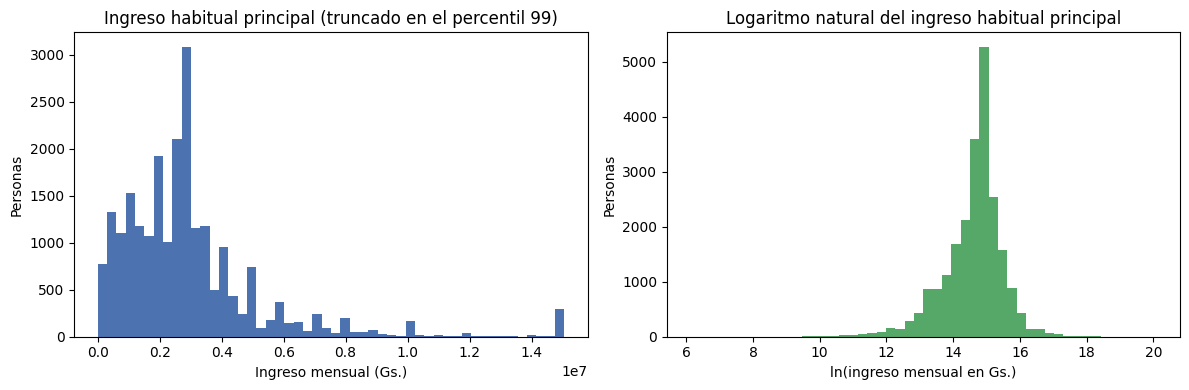

In [17]:
OBJETIVO = "INGRESO_HABITUAL_PRINCIPAL"
y_bruto = df[OBJETIVO]

# Estado del objetivo en la población de la Fase 2.
estado = pd.Series({
    "Personas en la población de análisis": len(y_bruto),
    "Objetivo faltante": int(y_bruto.isna().sum()),
    "Objetivo igual a 0": int(y_bruto.eq(0).sum()),
    "Objetivo mayor que 0": int(y_bruto.gt(0).sum()),
}, name="n")
display(estado.to_frame())

# Distribución del ingreso positivo, en guaraníes y en logaritmo.
pos = y_bruto[y_bruto.gt(0)]
print("Ingreso habitual principal (> 0), en Gs.:")
display(pos.describe(percentiles=[.001, .01, .05, .25, .5, .75, .95, .99, .999]).to_frame("Gs."))
print(f"Asimetría del ingreso en Gs.:  {pos.skew():,.2f}")
print(f"Asimetría del ln(ingreso):     {np.log(pos).skew():,.2f}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(pos.clip(upper=pos.quantile(0.99)), bins=50, color="#4C72B0")
ejes[0].set_title("Ingreso habitual principal (truncado en el percentil 99)")
ejes[0].set_xlabel("Ingreso mensual (Gs.)")
ejes[0].set_ylabel("Personas")
ejes[1].hist(np.log(pos), bins=50, color="#55A868")
ejes[1].set_title("Logaritmo natural del ingreso habitual principal")
ejes[1].set_xlabel("ln(ingreso mensual en Gs.)")
ejes[1].set_ylabel("Personas")
plt.tight_layout()
plt.show()

## 2.5 Tratamiento de los ingresos igual a cero y faltantes del objetivo

La Fase 2 dejó pendiente decidir qué hacer con los casos de ingreso cero antes de transformar. La decisión es:

- **Faltantes del objetivo:** se **excluyen**. No se imputa la variable que se quiere predecir, porque inventaría la respuesta que el modelo debe aprender.
- **Ingreso = 0:** se **excluyen**. El logaritmo no está definido en 0, y la alternativa `ln(1 + ingreso)` fabricaría una masa artificial de observaciones en `ln(1) = 0`, muy alejada del resto. La tabla siguiente muestra cómo se distribuyen estos ceros según `CATEGORIA_OCUPACIONAL`: la Fase 1 ya anticipaba que los trabajadores familiares no remunerados (`CATE_PEA == 5`) no tienen ingreso que comparar.

**Consecuencia para el alcance:** el modelo describe a los **ocupados de 18 a 60 años con ingreso laboral positivo**. Esta restricción adicional debe figurar en las limitaciones y en la conclusión de la Fase 3.

In [18]:
# Cómo se reparten los ingresos iguales a cero por categoría ocupacional.
display(pd.crosstab(df["CATEGORIA_OCUPACIONAL"], y_bruto.eq(0).rename("ingreso_cero"), margins=True))

# Base de modelado: solo ingreso positivo + objetivo en logaritmo.
n_inicial = len(df)
n_faltante = int(df[OBJETIVO].isna().sum())
n_cero = int(df[OBJETIVO].eq(0).sum())

df_modelo = df.loc[df[OBJETIVO].gt(0)].copy().reset_index(drop=True)
df_modelo["Y_LOG"] = np.log(df_modelo[OBJETIVO])

bitacora_objetivo = pd.DataFrame({
    "paso": ["Población de la Fase 2", "Se excluyen faltantes del objetivo",
             "Se excluyen ingresos iguales a 0", "Base de modelado"],
    "filas": [n_inicial, -n_faltante, -n_cero, len(df_modelo)],
})
display(bitacora_objetivo)
assert n_inicial - n_faltante - n_cero == len(df_modelo)

ingreso_cero,False,True,All
CATEGORIA_OCUPACIONAL,,,
1.000,2607,0,2607
2.000,10230,18,10248
3.000,1199,10,1209
4.000,6927,188,7115
5.000,0,1387,1387
6.000,1810,3,1813
All,22773,1606,24379


,paso,filas
0,Población de la Fase 2,24379
1,Se excluyen faltantes del objetivo,0
2,Se excluyen ingresos iguales a 0,-1606
3,Base de modelado,22773


# 3. Actividad 2 — Preparación de los datos para el modelado

## 3.1 Selección de variables fundamentada en las Fases 1 y 2

| Variable | Rol | Fundamento en las fases previas | Decisión |
|---|---|---|---|
| `ANIOS_ESTUDIO` | Educación (variable central) | Fase 1: gradiente educación-ingreso. Fase 2, H3: el ingreso sube en cada estrato (ANOVA y Tukey). Contiene más información que el estrato. | **Incluir** |
| `SEXO` | Predictor | Fase 2, H1 (brecha ≈ 45 %) y H4 (la brecha educativa difiere por sexo). | **Incluir**, más la interacción `ANIOS_ESTUDIO × SEXO` |
| `AREA` (urbana/rural) | Predictor | Fase 2, H2 (brecha ≈ 39 %). La interacción educación × área quedó como hipótesis pendiente. | **Incluir**, más `ANIOS_ESTUDIO × AREA` (exploratoria) |
| `EDAD` | Control | Recomendado en la Fase 2 (proxy de experiencia). Se agrega `EDAD²` para el perfil cóncavo edad-ingreso. | **Incluir** |
| `HORAS_SEMANALES_PRINCIPAL` | Control | Recomendado en la Fase 2: el ingreso mensual depende de la jornada. | **Incluir** |
| `CATEGORIA_OCUPACIONAL` | Control | Recomendado en la Fase 2 (asalariado, cuenta propia, empleador, etc.). | **Incluir** (categórica) |
| `INFORMALIDAD` | Calidad del empleo (OE3) | Hipótesis original de la Fase 1; la Fase 2 no la contrastó. | **Incluir**; su aporte se evaluará con la importancia de variables (Actividad 9) |
| `INGRESO_*` secundarios, otros y declarados | — | Son componentes o versiones del propio objetivo. | **Excluir** (fuga de información) |
| `estrato_educativo` | — | Deriva de `NIVEL_GRADO_MAX_APROBADO`, igual que `ANIOS_ESTUDIO`, pero con menos información. | **Excluir** como predictor; se conserva como metadato para el análisis de errores |
| `ID_*`, `UPM`, `NVIVI`, `NHOGA` | — | Identificadores. | **Excluir** como predictores; se usan solo para agrupar la partición (Actividad 3) |
| `FACTOR_EXPANSION` | — | Peso muestral, no característica de la persona. | **Excluir** como predictor; se conserva como metadato (la Fase 2 señaló que no se ponderó) |
| Rama, ocupación, tamaño del establecimiento | — | No evaluadas en las fases previas. Son canales por los que la educación actúa sobre el ingreso: incluirlas absorbería parte del efecto que se quiere medir. | **Excluir** en esta iteración |
| Demás variables de calidad del empleo (aportes, contrato, RUC, factura, seguros) | — | `INFORMALIDAD` ya las resume; incluirlas duplicaría información. | **Excluir** |

## 3.2 Codificación de variables categóricas

- **Binarias** (`SEXO`, `AREA`, `INFORMALIDAD`): se codifican 0/1 (`SEXO_MUJER`, `AREA_RURAL`, `INFORMAL`).
- **Nominal de varias categorías** (`CATEGORIA_OCUPACIONAL`): *one-hot*, con `handle_unknown="ignore"` para que una categoría ausente en entrenamiento no rompa la predicción. Los faltantes forman su propia categoría `sin_dato`. No se usa codificación ordinal, porque los códigos del INE no tienen orden.

## 3.3 Escalado

Se definen **dos preprocesadores**, porque el escalado solo es necesario según el algoritmo:

- **Lineal** (regresión lineal, Ridge/Lasso): variables numéricas **estandarizadas** (media 0, desvío 1), para que los coeficientes sean comparables y la penalización actúe por igual. Incluye `EDAD²` y las interacciones.
- **Árboles** (Random Forest, Gradient Boosting): **sin escalar**, porque los cortes de los árboles no dependen de la escala. No lleva `EDAD²` ni interacciones, que los árboles aprenden por sí solos.

## 3.4 Desbalance de clases

**No corresponde:** la tarea es de regresión y la variable objetivo es continua, por lo que no hay clases que balancear (no se aplica sobremuestreo ni submuestreo). El equivalente es que train y test tengan la misma distribución del objetivo; se logra en la partición estratificando por cuantiles del ingreso y se verifica en la Actividad 3.

## 3.5 Faltantes y fuga de información

Las imputaciones (mediana para numéricas, moda para binarias, `sin_dato` para categóricas) y el escalado se **ajustan solo con el conjunto de entrenamiento**. Por eso el preprocesador se define aquí, pero se ajusta **después** de la partición. Ajustarlo antes mezclaría información del conjunto de prueba en el entrenamiento. En la validación cruzada (Actividad 6) el preprocesador irá dentro de un `Pipeline`, de modo que se reajuste en cada pliegue.

In [19]:
# Transformaciones sin estado (no aprenden nada de los datos, por lo que no hay fuga de información).
df_modelo["SEXO_MUJER"] = df_modelo["SEXO_DESC"].map({"Mujer": 1, "Hombre": 0})
df_modelo["AREA_RURAL"] = df_modelo["AREA_DESC"].map({"Rural": 1, "Urbana": 0})
df_modelo["INFORMAL"] = df_modelo["INFORMALIDAD_DESC"].map({"Informal": 1, "Formal": 0})

df_modelo["EDAD2"] = df_modelo["EDAD"] ** 2
df_modelo["ANIOS_X_MUJER"] = df_modelo["ANIOS_ESTUDIO"] * df_modelo["SEXO_MUJER"]
df_modelo["ANIOS_X_RURAL"] = df_modelo["ANIOS_ESTUDIO"] * df_modelo["AREA_RURAL"]

# Categoría ocupacional como texto nominal (los faltantes quedan como NaN para imputarse luego).
df_modelo["CATEGORIA_OCUPACIONAL_CAT"] = (
    df_modelo["CATEGORIA_OCUPACIONAL"].round().astype("Int64").astype(str).replace("<NA>", np.nan)
)

# Conjuntos de variables por tipo de preprocesamiento.
NUM_LINEAL = ["ANIOS_ESTUDIO", "EDAD", "EDAD2", "HORAS_SEMANALES_PRINCIPAL", "ANIOS_X_MUJER", "ANIOS_X_RURAL"]
NUM_ARBOLES = ["ANIOS_ESTUDIO", "EDAD", "HORAS_SEMANALES_PRINCIPAL"]
BINARIAS = ["SEXO_MUJER", "AREA_RURAL", "INFORMAL"]
CATEGORICAS = ["CATEGORIA_OCUPACIONAL_CAT"]

CARACTERISTICAS = list(dict.fromkeys(NUM_LINEAL + NUM_ARBOLES + BINARIAS + CATEGORICAS))

def construir_preprocesador(numericas, binarias, categoricas, escalar):
    """ColumnTransformer sin ajustar: imputación (+ escalado opcional) y codificación."""
    pasos_num = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("escalar", StandardScaler()))
    pasos_cat = [
        ("imputar", SimpleImputer(strategy="constant", fill_value="sin_dato")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
    ct = ColumnTransformer(
        [
            ("num", Pipeline(pasos_num), numericas),
            ("bin", SimpleImputer(strategy="most_frequent"), binarias),
            ("cat", Pipeline(pasos_cat), categoricas),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return ct.set_output(transform="pandas")

preprocesador_lineal = construir_preprocesador(NUM_LINEAL, BINARIAS, CATEGORICAS, escalar=True)
preprocesador_arboles = construir_preprocesador(NUM_ARBOLES, BINARIAS, CATEGORICAS, escalar=False)

# Perfil de faltantes de las características (descriptivo; el ajuste de las imputaciones se hace solo con entrenamiento).
faltantes = (df_modelo[CARACTERISTICAS].isna().mean() * 100).round(2).rename("% faltante").to_frame()
faltantes["n faltantes"] = df_modelo[CARACTERISTICAS].isna().sum()
display(faltantes)

,% faltante,n faltantes
ANIOS_ESTUDIO,0.060,13
EDAD,0.000,0
EDAD2,0.000,0
HORAS_SEMANALES_PRINCIPAL,0.020,5
ANIOS_X_MUJER,0.060,13
ANIOS_X_RURAL,0.060,13
SEXO_MUJER,0.000,0
AREA_RURAL,0.000,0
INFORMAL,14.900,3393
CATEGORIA_OCUPACIONAL_CAT,0.000,0


# 4. Actividad 3 — Partición en entrenamiento y prueba

## 4.1 Criterio de partición

**¿Hay componente temporal?** No. La EPHC anual 2025 es un corte transversal y no contiene una fecha de observación (se documentó en la Fase 1, sección 4.7: `P08A` es el año de nacimiento, no un momento de observación). Por eso **no corresponde una partición cronológica**: no existe un "futuro" con el que se pudiera contaminar el entrenamiento.

**Sí hay dependencia entre observaciones, y es el riesgo que hay que controlar.** Las personas de un mismo hogar comparten área, vivienda, entorno y, muchas veces, ocupación e ingresos. La Fase 2 ya señaló esta dependencia. Con una partición aleatoria por persona, miembros del mismo hogar quedarían repartidos entre entrenamiento y prueba, y el modelo "reconocería" al hogar, lo que inflaría artificialmente la métrica de prueba.

**Partición adoptada:**
- **80 % entrenamiento / 20 % prueba**, con `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)`, tomando el primer pliegue como prueba.
- **Agrupada por hogar** (`UPM` + `NVIVI` + `NHOGA`): ningún hogar aparece en ambos conjuntos.
- **Estratificada por deciles de `Y_LOG`**: ambos conjuntos conservan la distribución del ingreso, incluida su cola.
- El conjunto de prueba **no se toca** hasta la evaluación final (Actividad 7). En la validación cruzada de la Actividad 6 se usará `GroupKFold` con los hogares de entrenamiento.

In [20]:
X = df_modelo[CARACTERISTICAS]
y = df_modelo["Y_LOG"]

# Metadatos: no son predictores; se conservan para el análisis de errores y la interpretación.
meta = df_modelo[["ID_PERSONA", OBJETIVO, "estrato_educativo", "SEXO_DESC", "AREA_DESC", "FACTOR_EXPANSION"]]

# Grupo = hogar (UPM + vivienda + hogar).
grupos = (df_modelo["ID_CONGLOMERADO_UPM"].astype(int).astype(str) + "-"
          + df_modelo["ID_VIVIENDA_NVIVI"].astype(int).astype(str) + "-"
          + df_modelo["ID_HOGAR_NHOGA"].astype(int).astype(str))
print(f"Personas: {len(grupos):,} | Hogares distintos: {grupos.nunique():,}")

# Estratos: deciles del objetivo.
estratos = pd.qcut(y, q=10, labels=False, duplicates="drop")

validador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(validador.split(X, estratos, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
meta_train, meta_test = meta.iloc[idx_train], meta.iloc[idx_test]
grupos_train, grupos_test = grupos.iloc[idx_train], grupos.iloc[idx_test]

# Verificaciones de la partición.
assert set(grupos_train).isdisjoint(set(grupos_test)), "Hay hogares en ambos conjuntos"
assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))

print(f"Entrenamiento: {len(X_train):,} personas ({len(X_train)/len(X):.1%}) en {grupos_train.nunique():,} hogares")
print(f"Prueba:        {len(X_test):,} personas ({len(X_test)/len(X):.1%}) en {grupos_test.nunique():,} hogares")
print("Hogares compartidos entre ambos conjuntos: 0")

# Se guarda la partición para reproducirla en las siguientes iteraciones.
particion = pd.DataFrame({
    "ID_PERSONA": meta["ID_PERSONA"].values,
    "conjunto": np.where(np.isin(np.arange(len(X)), idx_test), "prueba", "entrenamiento"),
})
particion.to_csv(DIR_SALIDA / "particion_train_test.csv", index=False)
print(f"Partición guardada en {DIR_SALIDA / 'particion_train_test.csv'}")

Personas: 22,773 | Hogares distintos: 13,586
Entrenamiento: 18,230 personas (80.1%) en 10,867 hogares
Prueba:        4,543 personas (19.9%) en 2,719 hogares
Hogares compartidos entre ambos conjuntos: 0
Partición guardada en output/fase3/particion_train_test.csv


## 4.2 Verificación: ¿train y test son comparables?

Se comparan la distribución del objetivo y la composición por sexo, área, informalidad y estrato educativo. Se espera que las diferencias sean pequeñas; si no lo fueran, habría que revisar la partición antes de modelar.

,Entrenamiento,Prueba,Diferencia (prueba - entrenamiento)
n,"18,230.000","4,543.000","-13,687.000"
Y_LOG media,14.604,14.599,-0.005
Y_LOG desvío,0.909,0.931,0.022
Y_LOG p10,13.454,13.455,0.001
Y_LOG mediana,14.771,14.786,0.015
Y_LOG p90,15.528,15.516,-0.012
Ingreso mediano (Gs.),"2,600,000.000","2,638,585.786","38,585.786"
% mujeres,42.150,42.571,0.421
% área rural,37.065,36.320,-0.746
% informal,59.952,60.165,0.213


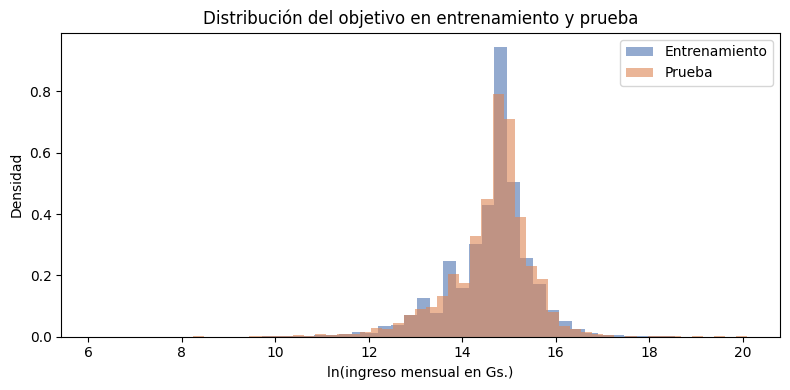

In [21]:
def describir(y_, X_, meta_):
    d = {
        "n": len(y_),
        "Y_LOG media": y_.mean(),
        "Y_LOG desvío": y_.std(),
        "Y_LOG p10": y_.quantile(.10),
        "Y_LOG mediana": y_.median(),
        "Y_LOG p90": y_.quantile(.90),
        "Ingreso mediano (Gs.)": meta_[OBJETIVO].median(),
        "% mujeres": X_["SEXO_MUJER"].mean() * 100,
        "% área rural": X_["AREA_RURAL"].mean() * 100,
        "% informal": X_["INFORMAL"].mean() * 100,
        "Años de estudio (media)": X_["ANIOS_ESTUDIO"].mean(),
        "Edad (media)": X_["EDAD"].mean(),
    }
    for est in ["sin/básica", "media", "terciaria/universitaria"]:
        d[f"% estrato {est}"] = meta_["estrato_educativo"].eq(est).mean() * 100
    return pd.Series(d)

comparacion = pd.DataFrame({
    "Entrenamiento": describir(y_train, X_train, meta_train),
    "Prueba": describir(y_test, X_test, meta_test),
})
comparacion["Diferencia (prueba - entrenamiento)"] = comparacion["Prueba"] - comparacion["Entrenamiento"]
display(comparacion)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_train, bins=50, density=True, alpha=0.6, label="Entrenamiento", color="#4C72B0")
ax.hist(y_test, bins=50, density=True, alpha=0.6, label="Prueba", color="#DD8452")
ax.set_title("Distribución del objetivo en entrenamiento y prueba")
ax.set_xlabel("ln(ingreso mensual en Gs.)")
ax.set_ylabel("Densidad")
ax.legend()
plt.tight_layout()
plt.show()

# 5. Ajuste de los preprocesadores (solo con entrenamiento)

Se ajustan los dos preprocesadores definidos en la Actividad 2 **solo con el conjunto de entrenamiento**; el de prueba únicamente se transforma, para comprobar que el procedimiento funciona. Estas matrices sirven para inspeccionar el resultado. En el modelado y en la validación cruzada los preprocesadores irán dentro de un `Pipeline`, que los reajusta en cada pliegue.

In [22]:
# Preprocesador lineal (con escalado).
X_train_lin = preprocesador_lineal.fit_transform(X_train)
X_test_lin = preprocesador_lineal.transform(X_test)

# Preprocesador para árboles (sin escalado).
X_train_arb = preprocesador_arboles.fit_transform(X_train)
X_test_arb = preprocesador_arboles.transform(X_test)

print(f"Lineal:  entrenamiento {X_train_lin.shape} | prueba {X_test_lin.shape}")
print(f"Árboles: entrenamiento {X_train_arb.shape} | prueba {X_test_arb.shape}")

# No debe quedar ningún faltante y ambas matrices deben tener las mismas columnas.
for nombre, M in [("lineal-train", X_train_lin), ("lineal-test", X_test_lin),
                  ("árboles-train", X_train_arb), ("árboles-test", X_test_arb)]:
    assert not M.isna().any().any(), f"Quedaron faltantes en {nombre}"
assert list(X_train_lin.columns) == list(X_test_lin.columns)
assert list(X_train_arb.columns) == list(X_test_arb.columns)

print("\nColumnas del preprocesador lineal:", list(X_train_lin.columns))

# Escalado: en entrenamiento las numéricas deben tener media ≈ 0 y desvío ≈ 1.
print("\nNuméricas estandarizadas (entrenamiento, preprocesador lineal):")
display(X_train_lin[NUM_LINEAL].agg(["mean", "std"]).T)

# Categorías poco frecuentes de CATEGORIA_OCUPACIONAL en entrenamiento.
print("Categoría ocupacional en entrenamiento (proporción):")
display(X_train["CATEGORIA_OCUPACIONAL_CAT"].fillna("sin_dato").value_counts(normalize=True).to_frame("proporción"))

Lineal:  entrenamiento (18230, 14) | prueba (4543, 14)
Árboles: entrenamiento (18230, 11) | prueba (4543, 11)

Columnas del preprocesador lineal: ['ANIOS_ESTUDIO', 'EDAD', 'EDAD2', 'HORAS_SEMANALES_PRINCIPAL', 'ANIOS_X_MUJER', 'ANIOS_X_RURAL', 'SEXO_MUJER', 'AREA_RURAL', 'INFORMAL', 'CATEGORIA_OCUPACIONAL_CAT_1', 'CATEGORIA_OCUPACIONAL_CAT_2', 'CATEGORIA_OCUPACIONAL_CAT_3', 'CATEGORIA_OCUPACIONAL_CAT_4', 'CATEGORIA_OCUPACIONAL_CAT_6']

Numéricas estandarizadas (entrenamiento, preprocesador lineal):


,mean,std
ANIOS_ESTUDIO,0.000,1.000
EDAD,0.000,1.000
EDAD2,-0.000,1.000
HORAS_SEMANALES_PRINCIPAL,-0.000,1.000
ANIOS_X_MUJER,0.000,1.000
ANIOS_X_RURAL,-0.000,1.000


Categoría ocupacional en entrenamiento (proporción):


,proporción
CATEGORIA_OCUPACIONAL_CAT,
2,0.450
4,0.305
1,0.112
6,0.079
3,0.053


## 5.1 Verificación empírica de la selección de variables (solo entrenamiento)

Como respaldo adicional a la selección de la sección 3.1, se calcula la correlación de Spearman entre cada predictor numérico o binario y el objetivo, **únicamente con el conjunto de entrenamiento**. Es un chequeo descriptivo y no reemplaza a la importancia de variables de la Actividad 9; no se usa para agregar ni quitar variables.

In [23]:
cols_corr = ["ANIOS_ESTUDIO", "EDAD", "HORAS_SEMANALES_PRINCIPAL", "SEXO_MUJER", "AREA_RURAL", "INFORMAL"]
corr_spearman = X_train[cols_corr].corrwith(y_train, method="spearman").sort_values(key=np.abs, ascending=False)
display(corr_spearman.to_frame("Spearman con Y_LOG (entrenamiento)"))

,Spearman con Y_LOG (entrenamiento)
INFORMAL,-0.523
ANIOS_ESTUDIO,0.406
HORAS_SEMANALES_PRINCIPAL,0.288
AREA_RURAL,-0.245
SEXO_MUJER,-0.165
EDAD,0.044


# 6. Resumen de decisiones de las Actividades 1 a 3

In [24]:
resumen = pd.DataFrame({
    "Decisión": [
        "Tipo de tarea",
        "Variable objetivo",
        "Vínculo con el proyecto",
        "Base de modelado",
        "Predictores (lineal)",
        "Predictores (árboles)",
        "Codificación",
        "Escalado",
        "Desbalance de clases",
        "Partición",
        "Semilla",
        "Tamaño entrenamiento / prueba",
    ],
    "Valor": [
        "Regresión",
        "ln(INGRESO_HABITUAL_PRINCIPAL)",
        "OE2 (principal), OE3 y OE4",
        f"Ocupados de 18-60 años con ingreso > 0 (n = {len(df_modelo):,})",
        ", ".join(NUM_LINEAL + BINARIAS + CATEGORICAS),
        ", ".join(NUM_ARBOLES + BINARIAS + CATEGORICAS),
        "Binarias 0/1; one-hot para categoría ocupacional (faltantes = 'sin_dato')",
        "StandardScaler solo en el preprocesador lineal",
        "No aplica (objetivo continuo)",
        "No temporal (corte transversal); 80/20 agrupada por hogar y estratificada por deciles del objetivo",
        str(SEMILLA),
        f"{len(X_train):,} / {len(X_test):,}",
    ],
})
with pd.option_context("display.max_colwidth", None):
    display(resumen)

,Decisión,Valor
0,Tipo de tarea,Regresión
1,Variable objetivo,ln(INGRESO_HABITUAL_PRINCIPAL)
2,Vínculo con el proyecto,"OE2 (principal), OE3 y OE4"
3,Base de modelado,"Ocupados de 18-60 años con ingreso > 0 (n = 22,773)"
4,Predictores (lineal),"ANIOS_ESTUDIO, EDAD, EDAD2, HORAS_SEMANALES_PRINCIPAL, ANIOS_X_MUJER, ANIOS_X_RURAL, SEXO_MUJER, AREA_RURAL, INFORMAL, CATEGORIA_OCUPACIONAL_CAT"
5,Predictores (árboles),"ANIOS_ESTUDIO, EDAD, HORAS_SEMANALES_PRINCIPAL, SEXO_MUJER, AREA_RURAL, INFORMAL, CATEGORIA_OCUPACIONAL_CAT"
6,Codificación,Binarias 0/1; one-hot para categoría ocupacional (faltantes = 'sin_dato')
7,Escalado,StandardScaler solo en el preprocesador lineal
8,Desbalance de clases,No aplica (objetivo continuo)
9,Partición,No temporal (corte transversal); 80/20 agrupada por hogar y estratificada por deciles del objetivo


## Notas y limitaciones de esta etapa

- **Alcance del modelo:** ocupados de 18 a 60 años **con ingreso laboral positivo**; no describe a desocupados, inactivos, trabajadores sin ingreso ni mayores de 60 años.
- **Faltantes en predictores:** se imputan con estadísticos del entrenamiento. Si la tabla de faltantes muestra una proporción relevante en alguna variable, conviene evaluar un indicador de faltante.
- **Interacciones:** `ANIOS_X_MUJER` se apoya en H4; `ANIOS_X_RURAL` es exploratoria, porque la Fase 2 no contrastó esa hipótesis.
- **Ponderación muestral:** no se pondera por `FACTOR_EXPANSION`, igual que en la Fase 2. Las métricas describen a la muestra, no a la población del país.
- **Próximas actividades:** línea base (Actividad 4), al menos tres familias de modelos (5), validación cruzada agrupada y búsqueda de hiperparámetros (6), evaluación única en prueba (7), análisis de errores (8) e interpretación (9).

## Declaración de uso de asistencia de IA
Se utilizó un asistente de IA como apoyo en la estructuración del notebook, la redacción y la depuración de código. Las decisiones metodológicas (tarea, variable objetivo, tratamiento de ceros, criterio de partición y selección de variables) son revisadas y asumidas por el grupo.